# Data Set Audit

# Load the DataSet

In [1]:
import pandas as pd
import numpy as np

# Load raw ChEMBL dataset
df = pd.read_csv("chembl_hia_raw_from_api.csv")

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Dataset loaded successfully.
Rows: 35,437
Columns: 9


In [2]:
# Column Names

df.columns.tolist()

['assay_chembl_id',
 'canonical_smiles',
 'molecule_chembl_id',
 'standard_type',
 'standard_units',
 'standard_value',
 'type',
 'units',
 'value']

# We have 9 columns:
- assay_chembl_id — assay identifier
- canonical_smiles — molecular structure
- molecule_chembl_id — molecule identifier
- standard_type — standardized endpoint name
- standard_units — standardized unit
- standard_value — standardized experimental value
- type — original reported endpoint type
- units — original reported units
- value — original reported value

# 3: Check Data Types

In [3]:
df.dtypes

assay_chembl_id        object
canonical_smiles       object
molecule_chembl_id     object
standard_type          object
standard_units         object
standard_value        float64
type                   object
units                  object
value                 float64
dtype: object

# 4 Basic Missing-Value Audit

In [4]:
df.isna().sum()

assay_chembl_id          0
canonical_smiles         0
molecule_chembl_id       0
standard_type            0
standard_units        1129
standard_value           0
type                     0
units                 1129
value                    0
dtype: int64

# 5 Check the Endpoint Types

In [5]:
df["standard_type"].value_counts()

standard_type
Papp                        17950
permeability                15235
logPapp                       916
Permeability                  564
Papp A to B (mean)            274
Drugabsorption                191
Absorption                    144
LogPapp                        38
Permeability coefficient       37
Caco-2 Papp                    34
Pcaco2                         14
Cell permeation                13
Papp e-6                        8
Papps                           7
Caco-2 permeability             4
Permeability rate               4
Caco-2 A-B                      3
PCaco-2                         1
Name: count, dtype: int64

# 6 — Examine the original type
This is important because standard_type is ChEMBL's standardized representation, while type contains the original endpoint wording.

In [6]:
df["type"].value_counts()

type
Papp                        17950
permeability                15235
logPapp                       916
Permeability                  564
Papp A to B (mean)            274
Drugabsorption                191
Absorption                    144
Log Papp                       38
Permeability coefficient       37
Caco-2 Papp                    34
Pcaco2                         14
Cell permeation                13
Papp e-6                        8
Papps                           7
Caco-2 permeability             4
Permeability rate               4
Caco-2 A-B                      3
PCaco-2                         1
Name: count, dtype: int64

# 7 — Examine standardized units

In [7]:
df["standard_units"].value_counts(dropna=False)

standard_units
10'-6 cm/s    8562
10^-6 cm/s    8010
ucm/s         6812
nm/s          6118
%             1168
              ... 
ug/cm2.hr        1
pmol/min         1
cm/min           1
10^-6m/s         1
ml/hr/kg         1
Name: count, Length: 107, dtype: int64

# 8 — Endpoint × unit relationship

In [8]:
pd.crosstab(
    df["standard_type"],
    df["standard_units"],
    dropna=False
)

standard_units,%,% hr-1,%/hr,*10e6,10'-2 cm/s,10'-3cm/min,10'-3cm/s,10'-4 cm/min,10'-4 cm/s,10'-5 cm/s,...,ug,ug ml-1,ug/cm2.hr,ug/g,ul min-1,um/s,umol cm2/hr,umol/L/s,umol/cm2/hr,NaN
standard_type,,,,,,,,,,,,,,,,,,,,,
Absorption,124,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,0,0
Caco-2 A-B,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Caco-2 Papp,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Caco-2 permeability,0,4,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Cell permeation,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Drugabsorption,169,0,0,0,0,0,0,0,0,0,...,0,0,0,7,0,0,0,0,0,0
LogPapp,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,38
PCaco-2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Papp,37,0,0,0,11,4,1,0,51,64,...,0,0,0,0,0,5,0,6,0,79


# 9 — Find the actual endpoint–unit combinations

In [9]:
endpoint_units = (
    df.groupby(["standard_type", "standard_units"])
      .size()
      .reset_index(name="count")
      .sort_values("count", ascending=False)
)

endpoint_units.head(30)

,standard_type,standard_units,count
43,Papp,10^-6 cm/s,4790
24,Papp,10'-6 cm/s,4553
69,Papp,ucm/s,4240
98,permeability,10'-6 cm/s,4009
136,permeability,nm/s,3344
113,permeability,10^-6 cm/s,3220
63,Papp,nm/s,2773
145,permeability,ucm/s,2572
91,permeability,%,838
86,Permeability,nm s-1,400


# 10 - Audit Papp Units Only

In [11]:
papp_units = (
    df[df["standard_type"] == "Papp"]["standard_units"]
    .value_counts(dropna=False)
)

papp_units

standard_units
10^-6 cm/s          4790
10'-6 cm/s          4553
ucm/s               4240
nm/s                2773
10'6cm/s             183
cm s-1               135
cm/s * 10E6          119
10'-7 cm/s           112
cm/s                 101
10'-5cm/s             91
NaN                   79
uL/hr/cm2             70
10'-5 cm/s            64
10^6cm/s              63
nM/s                  61
10^-8cm/s             54
10'-4 cm/s            51
10^7cm/s              50
10^-7 cm/s            45
10^-5cm/s             43
%                     37
10'-6/cm              26
nm s-1                25
10e-6 cm s-1          23
10'-8cm/s             20
10'-6nanometer/s      16
10'-2 cm/s            11
10-6 cm/s             11
10'-6cm/min           11
10'-6cm/s              9
10'-6cm/s2             8
cm min-1               8
10^-5 cm/s             7
umol/L/s               6
ucm                    6
um/s                   5
10'-3cm/min            4
cm'-6/s                4
10'-8m/s               4
nM s-1    

# 11 Examine Papp Value ranges by Unit

In [12]:
papp_value_summary = (
    df[df["standard_type"] == "Papp"]
    .groupby("standard_units")["standard_value"]
    .agg(["count", "min", "median", "max"])
    .sort_values("count", ascending=False)
)

papp_value_summary

,count,min,median,max
standard_units,,,,
10^-6 cm/s,4790,0.000000e+00,8.000,6.167500e+02
10'-6 cm/s,4553,0.000000e+00,8.900,2.250000e+02
ucm/s,4240,0.000000e+00,7.935,2.087000e+03
nm/s,2773,0.000000e+00,86.000,4.375440e+05
10'6cm/s,183,2.000000e-03,3.500,2.635500e+02
cm s-1,135,1.000000e-07,26.600,1.190000e+08
cm/s * 10E6,119,2.000000e-02,11.000,7.700000e+02
10'-7 cm/s,112,0.000000e+00,9.255,7.640000e+02
cm/s,101,5.000000e-02,9.400,1.200000e+02


# 1: Endpoint Definition

In [13]:
# Target endpoint for this study
TARGET_ENDPOINT = "Caco-2 apparent permeability (Papp)"

# Final target unit
TARGET_UNIT = "cm/s"

# Modeling target
TARGET_TRANSFORM = "log10(Papp)"

Let's go. Step 2 only: identify candidate Papp records.
We already know standard_type contains many different endpoint names. Before converting units, let's isolate the records whose endpoint names explicitly indicate Papp/permeability.

In [14]:
papp_keywords = [
    "Papp",
    "permeability",
    "Permeability",
    "Caco-2 Papp",
    "Pcaco2",
    "PCaco-2",
    "Papps"
]

papp_candidates = df[
    df["standard_type"].isin(papp_keywords)
].copy()

print("Candidate rows:", len(papp_candidates))
print("\nStandard types:")
print(papp_candidates["standard_type"].value_counts())

Candidate rows: 33805

Standard types:
standard_type
Papp            17950
permeability    15235
Permeability      564
Caco-2 Papp        34
Pcaco2             14
Papps               7
PCaco-2             1
Name: count, dtype: int64


Next step — inspect endpoint + unit together
Let's see how these 33,805 rows are distributed across standard_type × standard_units

In [15]:
endpoint_unit_summary = (
    papp_candidates
    .groupby(["standard_type", "standard_units"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

endpoint_unit_summary.head(30)

,standard_type,standard_units,count
28,Papp,10^-6 cm/s,4790
9,Papp,10'-6 cm/s,4553
54,Papp,ucm/s,4240
77,permeability,10'-6 cm/s,4009
115,permeability,nm/s,3344
92,permeability,10^-6 cm/s,3220
48,Papp,nm/s,2773
124,permeability,ucm/s,2572
70,permeability,%,838
68,Permeability,nm s-1,400


Let's create a list of all unique units used by our 33,805 candidate rows, rather than looking at the top 30.

In [16]:
papp_units = (
    papp_candidates["standard_units"]
    .value_counts()
    .rename_axis("standard_units")
    .reset_index(name="count")
)

papp_units

,standard_units,count
0,10'-6 cm/s,8562
1,10^-6 cm/s,8010
2,ucm/s,6812
3,nm/s,6118
4,%,875
...,...,...
89,10'-3cm/s,1
90,uL/min.mg,1
91,10^-6cm2/s,1
92,10'-6cm2/s,1


# 12- Keep the Four dominant units 

In [18]:
selected_units = [
    "10^-6 cm/s",
    "10'-6 cm/s",
    "ucm/s",
    "nm/s"
]

df_unit_filtered = papp_candidates[
    papp_candidates["standard_units"].isin(selected_units)
].copy()

print("Rows after unit filtering:", len(df_unit_filtered))

print("\nUnits:")
print(df_unit_filtered["standard_units"].value_counts())

Rows after unit filtering: 29502

Units:
standard_units
10'-6 cm/s    8562
10^-6 cm/s    8010
ucm/s         6812
nm/s          6118
Name: count, dtype: int64


# Next step
We need to determine whether these four unit labels actually represent the same physical unit and therefore can be safely converted to a common unit.

# Step 13 — Verify the four units are physically convertible
Before converting anything, let's inspect their meaning and value ranges together

In [19]:
unit_check = (
    papp_candidates[
        papp_candidates["standard_units"].isin([
            "10^-6 cm/s",
            "10'-6 cm/s",
            "ucm/s",
            "nm/s"
        ])
    ]
    .groupby("standard_units")["standard_value"]
    .agg(["count", "min", "median", "max"])
    .sort_values("count", ascending=False)
)

unit_check

,count,min,median,max
standard_units,,,,
10'-6 cm/s,8562,0.0,9.4,2704.0
10^-6 cm/s,8010,-4.5,7.9,2323.0
ucm/s,6812,0.0,8.2,2900.0
nm/s,6118,0.0,92.0,437544.0


- The first three have very similar median numerical values (~8–9), which strongly suggests they are different notations for the same scale: 10⁻⁶ cm/s.
nm/s is different numerically because its scale is different. It can potentially be converted to the same physical unit.

But we should NOT convert yet.
There is one issue we must investigate first:

- 10^-6 cm/s contains a negative minimum (-4.5).
- A negative permeability/Papp value is suspicious and needs to be handled explicitly during curation.

# 14 Inspect Negative Values

In [20]:
negative_papp = papp_candidates[
    papp_candidates["standard_units"].isin([
        "10^-6 cm/s",
        "10'-6 cm/s",
        "ucm/s",
        "nm/s"
    ])
    & (papp_candidates["standard_value"] < 0)
]

print("Negative values:", len(negative_papp))

negative_papp[
    [
        "canonical_smiles",
        "molecule_chembl_id",
        "standard_type",
        "standard_units",
        "standard_value"
    ]
].head(20)

Negative values: 6


,canonical_smiles,molecule_chembl_id,standard_type,standard_units,standard_value
32803,COc1ccccc1N1CCN(CCCCNC(=O)c2ccc(-c3ccccc3)cc2)CC1,CHEMBL112065,permeability,10^-6 cm/s,-3.9
32804,COc1ccccc1N1CCN(CCCCNC(=O)c2ccc(B3C=CC=CN3)cc2...,CHEMBL5281608,permeability,10^-6 cm/s,-4.3
32805,O=C(NCCS(=O)(=O)c1ccc(C(F)(F)F)cn1)c1ccc(-c2cc...,CHEMBL598609,permeability,10^-6 cm/s,-4.2
32806,O=C(NCCS(=O)(=O)c1ccc(C(F)(F)F)cn1)c1ccc(B2C=C...,CHEMBL5289407,permeability,10^-6 cm/s,-4.5
32807,O=C(Cc1ccc(-c2ccccc2)cc1)Nc1cc(C2CC2)[nH]n1,CHEMBL115933,permeability,10^-6 cm/s,-3.9
32808,O=C(Cc1ccc(B2C=CC=CN2)cc1)Nc1cc(C2CC2)[nH]n1,CHEMBL5200108,permeability,10^-6 cm/s,-4.5


# Inspect the Original Measurment fields

In [21]:
negative_papp[
    [
        "assay_chembl_id",
        "canonical_smiles",
        "molecule_chembl_id",
        "standard_type",
        "standard_units",
        "standard_value",
        "type",
        "units",
        "value"
    ]
]

,assay_chembl_id,canonical_smiles,molecule_chembl_id,standard_type,standard_units,standard_value,type,units,value
32803,CHEMBL5247301,COc1ccccc1N1CCN(CCCCNC(=O)c2ccc(-c3ccccc3)cc2)CC1,CHEMBL112065,permeability,10^-6 cm/s,-3.9,permeability,10^-6 cm/s,-3.9
32804,CHEMBL5247301,COc1ccccc1N1CCN(CCCCNC(=O)c2ccc(B3C=CC=CN3)cc2...,CHEMBL5281608,permeability,10^-6 cm/s,-4.3,permeability,10^-6 cm/s,-4.3
32805,CHEMBL5247301,O=C(NCCS(=O)(=O)c1ccc(C(F)(F)F)cn1)c1ccc(-c2cc...,CHEMBL598609,permeability,10^-6 cm/s,-4.2,permeability,10^-6 cm/s,-4.2
32806,CHEMBL5247301,O=C(NCCS(=O)(=O)c1ccc(C(F)(F)F)cn1)c1ccc(B2C=C...,CHEMBL5289407,permeability,10^-6 cm/s,-4.5,permeability,10^-6 cm/s,-4.5
32807,CHEMBL5247301,O=C(Cc1ccc(-c2ccccc2)cc1)Nc1cc(C2CC2)[nH]n1,CHEMBL115933,permeability,10^-6 cm/s,-3.9,permeability,10^-6 cm/s,-3.9
32808,CHEMBL5247301,O=C(Cc1ccc(B2C=CC=CN2)cc1)Nc1cc(C2CC2)[nH]n1,CHEMBL5200108,permeability,10^-6 cm/s,-4.5,permeability,10^-6 cm/s,-4.5


# 15 Remove the 6 Invalid Records

In [22]:
papp_candidates_clean = papp_candidates[
    papp_candidates["standard_units"].isin([
        "10^-6 cm/s",
        "10'-6 cm/s",
        "ucm/s",
        "nm/s"
    ])
    & (papp_candidates["standard_value"] > 0)
].copy()

print("Rows after removing invalid negative values:",
      len(papp_candidates_clean))

print("\nNegative values remaining:",
      (papp_candidates_clean["standard_value"] < 0).sum())

Rows after removing invalid negative values: 29151

Negative values remaining: 0


In [23]:
print("Original 4-unit rows:", len(
    papp_candidates[
        papp_candidates["standard_units"].isin([
            "10^-6 cm/s",
            "10'-6 cm/s",
            "ucm/s",
            "nm/s"
        ])
    ]
))

print("Clean dataset rows:", len(papp_candidates_clean))

print("\nRows by unit in clean dataset:")
print(papp_candidates_clean["standard_units"].value_counts())

Original 4-unit rows: 29502
Clean dataset rows: 29151

Rows by unit in clean dataset:
standard_units
10'-6 cm/s    8464
10^-6 cm/s    7920
ucm/s         6777
nm/s          5990
Name: count, dtype: int64


In [24]:
unit_values_check = (
    papp_candidates[
        papp_candidates["standard_units"].isin([
            "10^-6 cm/s",
            "10'-6 cm/s",
            "ucm/s",
            "nm/s"
        ])
    ]
    .groupby("standard_units")["standard_value"]
    .agg(
        total="count",
        zero=lambda x: (x == 0).sum(),
        negative=lambda x: (x < 0).sum(),
        positive=lambda x: (x > 0).sum()
    )
)

unit_values_check

,total,zero,negative,positive
standard_units,,,,
10'-6 cm/s,8562,98,0,8464
10^-6 cm/s,8010,84,6,7920
nm/s,6118,128,0,5990
ucm/s,6812,35,0,6777


# 16 Standardize the units

We'll convert everything to one common scale:

- Papp = ×10⁻⁶ cm/s
The conversion is:
- 10^-6 cm/s → unchanged
- 10'-6 cm/s → unchanged
- ucm/s → unchanged
- nm/s → multiply by 0.1

In [25]:
papp_candidates_clean["papp_u6_cm_s"] = (
    papp_candidates_clean["standard_value"]
    * papp_candidates_clean["standard_units"].map({
        "10^-6 cm/s": 1.0,
        "10'-6 cm/s": 1.0,
        "ucm/s": 1.0,
        "nm/s": 0.1
    })
)

print(papp_candidates_clean[
    ["standard_units", "standard_value", "papp_u6_cm_s"]
].head(20))

    standard_units  standard_value  papp_u6_cm_s
340           nm/s           50.00          5.00
341           nm/s           50.00          5.00
342           nm/s           50.00          5.00
343           nm/s           50.00          5.00
344           nm/s           50.00          5.00
345           nm/s           50.00          5.00
346           nm/s           50.00          5.00
347           nm/s           50.00          5.00
348           nm/s           50.00          5.00
349           nm/s           50.00          5.00
350           nm/s           10.00          1.00
351           nm/s           50.00          5.00
352           nm/s           50.00          5.00
353           nm/s           10.00          1.00
354           nm/s           10.00          1.00
355          ucm/s           35.00         35.00
356          ucm/s           42.00         42.00
358          ucm/s            2.66          2.66
359          ucm/s           16.81         16.81
360          ucm/s  

# inspect the nm/s records

In [26]:
nm_records = papp_candidates_clean[
    papp_candidates_clean["standard_units"] == "nm/s"
]

print(nm_records[
    [
        "assay_chembl_id",
        "molecule_chembl_id",
        "standard_type",
        "standard_units",
        "standard_value",
        "type",
        "units",
        "value"
    ]
].head(20))

    assay_chembl_id molecule_chembl_id standard_type standard_units  \
340    CHEMBL880470          CHEMBL563          Papp           nm/s   
341    CHEMBL880470       CHEMBL196279          Papp           nm/s   
342    CHEMBL880470       CHEMBL195970          Papp           nm/s   
343    CHEMBL880472       CHEMBL264006          Papp           nm/s   
344    CHEMBL880470       CHEMBL194274          Papp           nm/s   
345    CHEMBL880470       CHEMBL196321          Papp           nm/s   
346    CHEMBL880470       CHEMBL380778          Papp           nm/s   
347    CHEMBL880470       CHEMBL197202          Papp           nm/s   
348    CHEMBL880470       CHEMBL194760          Papp           nm/s   
349    CHEMBL880470       CHEMBL196946          Papp           nm/s   
350    CHEMBL880470       CHEMBL372751          Papp           nm/s   
351    CHEMBL880470       CHEMBL196947          Papp           nm/s   
352    CHEMBL880470       CHEMBL372846          Papp           nm/s   
353   

# let's convert all 4 units and then inspect the resulting distribution/outliers before any further row removal.

# Create one unified Papp values

In [27]:
conversion = {
    "10^-6 cm/s": 1.0,
    "10'-6 cm/s": 1.0,
    "ucm/s": 1.0,
    "nm/s": 0.1
}

clean_df = papp_candidates[
    papp_candidates["standard_units"].isin(conversion.keys())
].copy()

clean_df["papp_u6_cm_s"] = (
    clean_df["standard_value"]
    * clean_df["standard_units"].map(conversion)
)

print("Rows:", len(clean_df))
print(clean_df[
    ["standard_units", "standard_value", "papp_u6_cm_s"]
].head(20))

Rows: 29502
    standard_units  standard_value  papp_u6_cm_s
340           nm/s           50.00          5.00
341           nm/s           50.00          5.00
342           nm/s           50.00          5.00
343           nm/s           50.00          5.00
344           nm/s           50.00          5.00
345           nm/s           50.00          5.00
346           nm/s           50.00          5.00
347           nm/s           50.00          5.00
348           nm/s           50.00          5.00
349           nm/s           50.00          5.00
350           nm/s           10.00          1.00
351           nm/s           50.00          5.00
352           nm/s           50.00          5.00
353           nm/s           10.00          1.00
354           nm/s           10.00          1.00
355          ucm/s           35.00         35.00
356          ucm/s           42.00         42.00
358          ucm/s            2.66          2.66
359          ucm/s           16.81         16.81
360     

# check the Converted Values

In [28]:
clean_df["papp_u6_cm_s"].describe()

count    29502.000000
mean        40.558733
std        412.342216
min         -4.500000
25%          1.810000
50%          8.607500
75%         22.000000
max      43754.400000
Name: papp_u6_cm_s, dtype: float64

In [29]:
clean_df["papp_u6_cm_s"].value_counts().head(20)

papp_u6_cm_s
1.0     538
0.1     444
10.0    395
0.0     345
0.2     312
1.5     298
2.0     292
11.0    267
12.0    263
13.0    258
0.5     251
14.0    250
3.0     239
17.0    238
16.0    237
0.4     228
15.0    228
20.0    227
0.3     217
23.0    215
Name: count, dtype: int64

# — verify the non-positive values after conversion

In [30]:
non_positive = clean_df[
    clean_df["papp_u6_cm_s"] <= 0
]

print("Non-positive records:", len(non_positive))

print("\nBy value:")
print(non_positive["papp_u6_cm_s"].value_counts())

print("\nBy original unit:")
print(non_positive["standard_units"].value_counts())

Non-positive records: 351

By value:
papp_u6_cm_s
 0.0    345
-3.9      2
-4.5      2
-4.3      1
-4.2      1
Name: count, dtype: int64

By original unit:
standard_units
nm/s          128
10'-6 cm/s     98
10^-6 cm/s     90
ucm/s          35
Name: count, dtype: int64


In [31]:
clean_df = clean_df[
    clean_df["papp_u6_cm_s"] > 0
].copy()

print("Final positive-Papp records:", len(clean_df))

Final positive-Papp records: 29151


In [32]:
clean_df.to_csv(
    "02_Caco2_Papp_Curated.csv",
    index=False
)

In [1]:
import pandas as pd
import numpy as np


clean_df = pd.read_csv("02_Caco2_Papp_Curated.csv")

print("Rows:", len(clean_df))
print("Columns:", len(clean_df.columns))

Rows: 29151
Columns: 10


# Next step — unique molecules

We need to know whether multiple experimental measurements exist for the same molecule.

In [2]:
clean_df["canonical_smiles"].nunique()

21077

# Let's see how many measurements each molecule has.

In [3]:
measurement_counts = (
    clean_df["canonical_smiles"]
    .value_counts()
)

measurement_counts.describe()

count    21077.000000
mean         1.383072
std          2.366788
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        115.000000
Name: count, dtype: float64

# identify how widespread the repeats are

This will tell us:

how many molecules have 1 measurement

how many have 2

how many have 3

In [4]:
measurement_counts.value_counts().sort_index().head(15)

count
1     16427
2      3838
3       327
4       291
5        50
6        35
7        14
8        23
9         6
10        9
11        5
12        4
13        3
14        3
15        1
Name: count, dtype: int64

 # one simple audit
Let's take molecules with exactly 2 measurements and see whether their values are similar or substantially different.

In [5]:
duplicate_2 = clean_df[
    clean_df["canonical_smiles"].isin(
        measurement_counts[measurement_counts == 2].index
    )
]

duplicate_2.groupby("canonical_smiles")["papp_u6_cm_s"].agg(
    ["count", "min", "max", "mean", "std"]
).head(20)

,count,min,max,mean,std
canonical_smiles,,,,,
Br.CN(C)S(=O)(=O)c1ccc(Sc2ccc(F)cc2CSC(=N)N)c(CSC(=N)N)c1,2,0.10,0.10,0.10,0.000000
Br.COc1ccc(Sc2ccc(F)cc2CSC(=N)N)c(CSC(=N)N)c1,2,2.40,2.40,2.40,0.000000
Br.CS(=O)(=O)c1ccc(Sc2ccc(F)cc2CSC(=N)N)c(CSC(=N)N)c1,2,0.10,0.10,0.10,0.000000
Br.Cc1c2c(cc[n+]1Cc1ccccc1)c1ccc(OCC(=O)OCCCCOc3no[n+]([O-])c3S(=O)(=O)c3ccccc3)cc1n2CCCc1ccccc1,2,0.05,0.05,0.05,0.000000
Br.Cc1ccc(Sc2ccccc2CSC(=N)N)c(CSC(=N)N)c1,2,1.40,1.50,1.45,0.070711
Br.N=C(N)SCc1c(Br)ccc2c1oc1c(CSC(=N)N)c(Br)ccc12,2,0.10,0.20,0.15,0.070711
Br.N=C(N)SCc1c(Br)ccc2c1sc1c(CSC(=N)N)c(Br)ccc12,2,2.00,4.00,3.00,1.414214
Br.N=C(N)SCc1c(Cl)ccc2c1oc1c(CSC(=N)N)c(Cl)ccc12,2,0.10,0.40,0.25,0.212132
Br.N=C(N)SCc1c(F)ccc2c1oc1c(CSC(=N)N)c(F)ccc12,2,1.00,5.00,3.00,2.828427


We first quantify how many repeated molecules have:

# A. identical measurements

versus

# B. different measurements

Then we can establish a transparent aggregation rule.

In [6]:
duplicate_summary = (
    clean_df.groupby("canonical_smiles")["papp_u6_cm_s"]
    .agg(["count", "nunique"])
)

print("Repeated molecules:", (duplicate_summary["count"] > 1).sum())
print("Repeated molecules with identical values:",
      ((duplicate_summary["count"] > 1) &
       (duplicate_summary["nunique"] == 1)).sum())
print("Repeated molecules with different values:",
      ((duplicate_summary["count"] > 1) &
       (duplicate_summary["nunique"] > 1)).sum())

Repeated molecules: 4650
Repeated molecules with identical values: 342
Repeated molecules with different values: 4308


- Out of 21,077 unique molecules:
- 4,650 molecules have repeated measurements.
- 342 molecules have repeated measurements with exactly the same Papp.
- 4,308 molecules have different Papp values across measurements.

So the important point is:
- 
Most repeated molecules are not simply duplicate rows. They contain different experimental Papp values.

# Next step
Let's quantify the variation among those 4,308 molecules.

In [7]:
repeated_diff = duplicate_summary[
    (duplicate_summary["count"] > 1) &
    (duplicate_summary["nunique"] > 1)
]

print(repeated_diff[["count", "nunique"]].describe())

             count      nunique
count  4308.000000  4308.000000
mean      2.790390     2.583565
std       4.982899     3.380070
min       2.000000     2.000000
25%       2.000000     2.000000
50%       2.000000     2.000000
75%       2.000000     2.000000
max     115.000000    98.000000


So our next step should be:

Repeated-molecule analysis 

- quantify experimental variability 
- decide how to aggregate repeated measurements
- molecule-level train/test split.

# How much does Papp vary for the same molecule?

# Step 1 — Calculate variability for each repeated molecule

In [9]:
# Repeated molecules with different Papp values
repeat_analysis = (
    clean_df
    .groupby("canonical_smiles")["papp_u6_cm_s"]
    .agg(
        n_measurements="count",
        n_unique="nunique",
        min_value="min",
        max_value="max",
        mean_value="mean",
        median_value="median",
        std_value="std"
    )
    .query("n_unique > 1")
    .copy()
)

repeat_analysis["range"] = (
    repeat_analysis["max_value"] - repeat_analysis["min_value"]
)

repeat_analysis["log10_range"] = (
    np.log10(repeat_analysis["max_value"])
    - np.log10(repeat_analysis["min_value"])
)

repeat_analysis.head(20)

,n_measurements,n_unique,min_value,max_value,mean_value,median_value,std_value,range,log10_range
canonical_smiles,,,,,,,,,
Br.Cc1ccc(Sc2ccccc2CSC(=N)N)c(CSC(=N)N)c1,2,2,1.4,1.5,1.45,1.45,0.070711,0.1,0.029963
Br.N=C(N)SCc1c(Br)ccc2c1oc1c(CSC(=N)N)c(Br)ccc12,2,2,0.1,0.2,0.15,0.15,0.070711,0.1,0.301030
Br.N=C(N)SCc1c(Br)ccc2c1sc1c(CSC(=N)N)c(Br)ccc12,2,2,2.0,4.0,3.00,3.00,1.414214,2.0,0.301030
Br.N=C(N)SCc1c(Cl)ccc2c1oc1c(CSC(=N)N)c(Cl)ccc12,2,2,0.1,0.4,0.25,0.25,0.212132,0.3,0.602060
Br.N=C(N)SCc1c(F)ccc2c1oc1c(CSC(=N)N)c(F)ccc12,2,2,1.0,5.0,3.00,3.00,2.828427,4.0,0.698970
Br.N=C(N)SCc1cc(F)cc2c1sc1c(CSC(=N)N)cc(Cl)cc12,2,2,0.2,0.5,0.35,0.35,0.212132,0.3,0.397940
Br.N=C(N)SCc1cc(F)ccc1Oc1cc(Cl)ccc1CSC(=N)N,2,2,0.2,0.9,0.55,0.55,0.494975,0.7,0.653213
Br.N=C(N)SCc1cc(F)ccc1Oc1cc(F)ccc1CSC(=N)N,2,2,0.1,0.4,0.25,0.25,0.212132,0.3,0.602060
Br.N=C(N)SCc1cc(F)ccc1Oc1ccc(F)cc1CSC(=N)N,2,2,0.1,0.2,0.15,0.15,0.070711,0.1,0.301030


# Step 2 — Get the overall distribution

In [10]:
repeat_analysis[[
    "n_measurements",
    "n_unique",
    "range",
    "log10_range"
]].describe()

,n_measurements,n_unique,range,log10_range
count,4308.000000,4308.000000,4308.000000,4308.000000
mean,2.790390,2.583565,51.033478,0.629984
std,4.982899,3.380070,686.945142,0.612298
min,2.000000,2.000000,0.001000,0.000170
25%,2.000000,2.000000,2.337500,0.148939
50%,2.000000,2.000000,8.000000,0.414973
75%,2.000000,2.000000,22.100000,0.956193
max,115.000000,98.000000,31829.900000,4.623249


In [11]:
repeat_analysis["log10_range"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    4308.000000
mean        0.629984
std         0.612298
min         0.000170
25%         0.148939
50%         0.414973
75%         0.956193
90%         1.494850
95%         1.843016
99%         2.619308
max         4.623249
Name: log10_range, dtype: float64

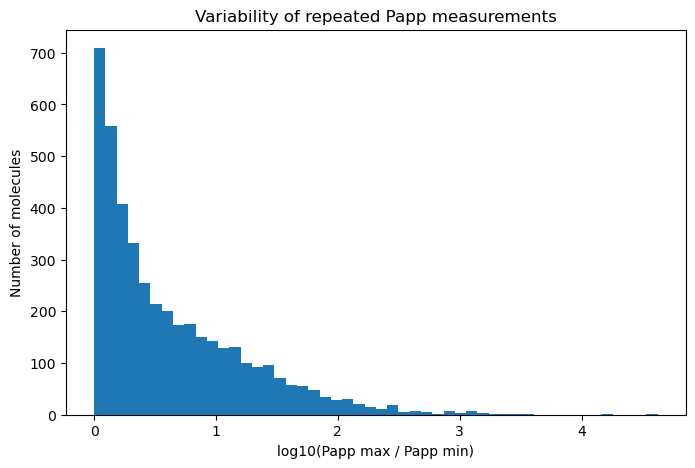

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    repeat_analysis["log10_range"],
    bins=50
)

plt.xlabel("log10(Papp max / Papp min)")
plt.ylabel("Number of molecules")
plt.title("Variability of repeated Papp measurements")

plt.show()

- What the plot tells us
- The distribution is strongly right-skewed:
- Most repeated molecules have small-to-moderate variation.
- The number of molecules decreases progressively as variation increases.
- There is a long tail extending beyond log₁₀ range 3 and up to ~4.6.
- So only a relatively small subset has extremely large variability.

Let's quantify the tail

- Rather than choosing an arbitrary cutoff, let's see exactly how many molecules fall into different variability levels.

In [13]:
thresholds = [0.3, 0.5, 1.0, 1.5, 2.0, 3.0]

for t in thresholds:
    n = (repeat_analysis["log10_range"] > t).sum()
    pct = n / len(repeat_analysis) * 100
    print(f"> {t:.1f}: {n} molecules ({pct:.2f}%)")

> 0.3: 2575 molecules (59.77%)
> 0.5: 1954 molecules (45.36%)
> 1.0: 1011 molecules (23.47%)
> 1.5: 427 molecules (9.91%)
> 2.0: 159 molecules (3.69%)
> 3.0: 19 molecules (0.44%)


# Are the large differences occurring because the same molecule was tested in different assays/experimental conditions?

# Repeated molecule → number of assays → variability within/between assays.

In [14]:
# Number of different assays for each repeated molecule
assay_variability = (
    clean_df
    .groupby("canonical_smiles")
    .agg(
        n_measurements=("papp_u6_cm_s", "count"),
        n_assays=("assay_chembl_id", "nunique"),
        n_values=("papp_u6_cm_s", "nunique"),
        min_papp=("papp_u6_cm_s", "min"),
        max_papp=("papp_u6_cm_s", "max")
    )
    .query("n_values > 1")
    .copy()
)

assay_variability.head(20)

,n_measurements,n_assays,n_values,min_papp,max_papp
canonical_smiles,,,,,
Br.Cc1ccc(Sc2ccccc2CSC(=N)N)c(CSC(=N)N)c1,2,2,2,1.4,1.5
Br.N=C(N)SCc1c(Br)ccc2c1oc1c(CSC(=N)N)c(Br)ccc12,2,2,2,0.1,0.2
Br.N=C(N)SCc1c(Br)ccc2c1sc1c(CSC(=N)N)c(Br)ccc12,2,2,2,2.0,4.0
Br.N=C(N)SCc1c(Cl)ccc2c1oc1c(CSC(=N)N)c(Cl)ccc12,2,2,2,0.1,0.4
Br.N=C(N)SCc1c(F)ccc2c1oc1c(CSC(=N)N)c(F)ccc12,2,2,2,1.0,5.0
Br.N=C(N)SCc1cc(F)cc2c1sc1c(CSC(=N)N)cc(Cl)cc12,2,2,2,0.2,0.5
Br.N=C(N)SCc1cc(F)ccc1Oc1cc(Cl)ccc1CSC(=N)N,2,2,2,0.2,0.9
Br.N=C(N)SCc1cc(F)ccc1Oc1cc(F)ccc1CSC(=N)N,2,2,2,0.1,0.4
Br.N=C(N)SCc1cc(F)ccc1Oc1ccc(F)cc1CSC(=N)N,2,2,2,0.1,0.2


In [15]:
assay_variability["n_assays"].value_counts().sort_index()

n_assays
1        85
2      3451
3       308
4       278
5        48
6        31
7        13
8        22
9         7
10        9
11        4
12        4
13        3
14        4
15        1
16        1
17        1
19        1
20        1
22        2
24        1
25        3
26        2
28        2
29        2
30        2
34        2
36        1
37        1
39        2
40        1
41        1
45        1
47        2
58        1
60        1
65        1
71        1
75        1
83        1
87        1
88        1
109       1
110       1
113       1
Name: count, dtype: int64

# For our Caco-2 chemical-space research, variation itself can represent experimental uncertainty.

I suggest our next step

Before deciding what to remove, let's determine:

1. Are different values coming from different assays?

2. Within the same assay, are repeated values consistent?

3. Across different assays, how much does Papp vary?

In [17]:
# Analyze repeated molecules at assay level

repeat_assay_analysis = (
    clean_df
    .groupby("canonical_smiles")
    .agg(
        n_measurements=("papp_u6_cm_s", "count"),
        n_assays=("assay_chembl_id", "nunique"),
        n_values=("papp_u6_cm_s", "nunique"),
        min_papp=("papp_u6_cm_s", "min"),
        max_papp=("papp_u6_cm_s", "max")
    )
)

repeat_assay_analysis = (
    repeat_assay_analysis[
        repeat_assay_analysis["n_values"] > 1
    ]
    .copy()
)

repeat_assay_analysis["log10_range"] = (
    np.log10(repeat_assay_analysis["max_papp"])
    - np.log10(repeat_assay_analysis["min_papp"])
)

repeat_assay_analysis.head(20)

,n_measurements,n_assays,n_values,min_papp,max_papp,log10_range
canonical_smiles,,,,,,
Br.Cc1ccc(Sc2ccccc2CSC(=N)N)c(CSC(=N)N)c1,2,2,2,1.4,1.5,0.029963
Br.N=C(N)SCc1c(Br)ccc2c1oc1c(CSC(=N)N)c(Br)ccc12,2,2,2,0.1,0.2,0.301030
Br.N=C(N)SCc1c(Br)ccc2c1sc1c(CSC(=N)N)c(Br)ccc12,2,2,2,2.0,4.0,0.301030
Br.N=C(N)SCc1c(Cl)ccc2c1oc1c(CSC(=N)N)c(Cl)ccc12,2,2,2,0.1,0.4,0.602060
Br.N=C(N)SCc1c(F)ccc2c1oc1c(CSC(=N)N)c(F)ccc12,2,2,2,1.0,5.0,0.698970
Br.N=C(N)SCc1cc(F)cc2c1sc1c(CSC(=N)N)cc(Cl)cc12,2,2,2,0.2,0.5,0.397940
Br.N=C(N)SCc1cc(F)ccc1Oc1cc(Cl)ccc1CSC(=N)N,2,2,2,0.2,0.9,0.653213
Br.N=C(N)SCc1cc(F)ccc1Oc1cc(F)ccc1CSC(=N)N,2,2,2,0.1,0.4,0.602060
Br.N=C(N)SCc1cc(F)ccc1Oc1ccc(F)cc1CSC(=N)N,2,2,2,0.1,0.2,0.301030


In [19]:
molecule_papp = (
    clean_df
    .groupby("canonical_smiles")
    .agg(
        n_measurements=("papp_u6_cm_s", "count"),
        n_assays=("assay_chembl_id", "nunique"),
        min_papp=("papp_u6_cm_s", "min"),
        max_papp=("papp_u6_cm_s", "max"),
        median_papp=("papp_u6_cm_s", "median"),
        mean_papp=("papp_u6_cm_s", "mean")
    )
    .reset_index()
)

molecule_papp["log10_range"] = (
    np.log10(molecule_papp["max_papp"])
    - np.log10(molecule_papp["min_papp"])
)

molecule_papp.shape

(21077, 8)

# let's inspect the distribution of the molecule-level Papp values.

In [20]:
molecule_papp["median_papp"].describe()

count    21077.000000
mean        43.113995
std        326.345239
min          0.000100
25%          2.295500
50%          9.400000
75%         23.000000
max      27839.450000
Name: median_papp, dtype: float64

- 21,077 molecules
- Median Papp = 9.4 × 10⁻⁶ cm/s
- 25th percentile = 2.30
- 75th percentile = 23.0
- Maximum = 27,839.45
- Mean (43.11) is much higher than the median → the distribution is strongly right-skewed.

# Let's see the distribution on a log10 scale, which is much more appropriate for permeability data.

In [21]:
molecule_papp["log10_median_papp"] = np.log10(
    molecule_papp["median_papp"]
)

molecule_papp["log10_median_papp"].describe()

count    21077.000000
mean         0.837130
std          0.826761
min         -4.000000
25%          0.360877
50%          0.973128
75%          1.361728
max          4.444661
Name: log10_median_papp, dtype: float64

# Next step — still just audit
Let's check whether there are any extreme values in the molecule-level dataset that came from only one measurement versus repeated measurements.

In [22]:
molecule_papp.groupby("n_measurements")["log10_median_papp"].agg(
    ["count", "min", "median", "max"]
)

,count,min,median,max
n_measurements,,,,
1,16427,-4.000000,0.934498,3.462398
2,3838,-2.000000,1.098644,4.444661
3,327,-1.920819,0.949390,3.131939
4,291,-1.221849,1.149219,2.848497
5,50,-1.698970,0.161110,1.685742
6,35,-0.190440,0.574031,1.622732
7,14,-1.045757,0.945880,2.139879
8,23,-2.769551,0.588832,1.962843
9,6,-1.000000,0.469010,0.826075


- The majority of molecules have only one measurement:
- 16,427 / 21,077 = 77.9% → one measurement
- 3,838 = 18.2% → two measurements
- 327 = 1.6% → three measurements
- The remaining molecules have more measurements.
- So our dataset is predominantly single-measurement molecules

In [23]:
molecule_papp["mean_median_ratio"] = (
    molecule_papp["mean_papp"] / molecule_papp["median_papp"]
)

molecule_papp["mean_median_ratio"].describe()

count    21077.000000
mean         1.076664
std          3.300249
min          0.669697
25%          1.000000
50%          1.000000
75%          1.000000
max        435.253623
Name: mean_median_ratio, dtype: float64

- This supports our approach
- For the molecule-level target, median Papp is a sensible robust choice because:
- Most molecules aren't affected.
- It reduces the influence of extreme repeated measurements.
- It avoids deleting those molecules from the dataset.
- We retain the variability information separately through log10_range.

We should inspect the molecules where the mean/median ratio is extremely high. That's a small but potentially important group.

In [25]:
thresholds = [2, 5, 10, 50, 100]

for t in thresholds:
    n = (molecule_papp["mean_median_ratio"] > t).sum()
    pct = n / len(molecule_papp) * 100
    print(f"> {t}×: {n} molecules ({pct:.2f}%)")

> 2×: 169 molecules (0.80%)
> 5×: 59 molecules (0.28%)
> 10×: 31 molecules (0.15%)
> 50×: 4 molecules (0.02%)
> 100×: 2 molecules (0.01%)


- duplicate structures / salts and representations
- missing/invalid SMILES
- chemical validity
- potentially unusual Papp values
- final dataset consistency

# next audit: SMILES validity

In [26]:
# Next audit: SMILES validity

from rdkit import Chem

molecule_papp["mol"] = molecule_papp["canonical_smiles"].apply(
    Chem.MolFromSmiles
)

print("Total molecules:", len(molecule_papp))
print("Valid SMILES:", molecule_papp["mol"].notna().sum())
print("Invalid SMILES:", molecule_papp["mol"].isna().sum())

Total molecules: 21077
Valid SMILES: 21077
Invalid SMILES: 0


# Next audit step: duplicate structures

In [27]:
molecule_papp["rdkit_canonical_smiles"] = molecule_papp["mol"].apply(
    Chem.MolToSmiles
)

print("Original unique SMILES:", molecule_papp["canonical_smiles"].nunique())
print("RDKit canonical structures:", molecule_papp["rdkit_canonical_smiles"].nunique())

Original unique SMILES: 21077
RDKit canonical structures: 21077


# Let's check for missing value

In [28]:
molecule_papp.isna().sum()

canonical_smiles          0
n_measurements            0
n_assays                  0
min_papp                  0
max_papp                  0
median_papp               0
mean_papp                 0
log10_range               0
log10_median_papp         0
mean_median_ratio         0
mol                       0
rdkit_canonical_smiles    0
dtype: int64

# Next step: chemical structure standardization

Before calculating Morgan fingerprints/descriptors, we should check salts and disconnected molecular fragments.

In [29]:
molecule_papp["n_fragments"] = molecule_papp["mol"].apply(
    lambda mol: len(Chem.GetMolFrags(mol))
)

print(molecule_papp["n_fragments"].value_counts().sort_index())

n_fragments
1    20449
2      523
3       80
4       16
5        9
Name: count, dtype: int64


- 20,449 (97.0%) are single-component structures.
- 628 (3.0%) contain multiple disconnected components.

What are those additional fragments?
We'll inspect the composition before deciding whether to standardize/remove them.
Next step — just quantify

In [30]:
multi_fragment = molecule_papp[
    molecule_papp["n_fragments"] > 1
].copy()

print("Multi-fragment molecules:", len(multi_fragment))

print(
    multi_fragment["canonical_smiles"]
    .head(20)
    .to_string(index=False)
)

Multi-fragment molecules: 628
          Br.CN(C)Cc1cc2c([nH]c(=O)c3cccc(O)c32)s1
Br.CN(C)S(=O)(=O)c1ccc(Sc2ccc(F)cc2CSC(=N)N)c(C...
     Br.COc1ccc(Sc2ccc(F)cc2CSC(=N)N)c(CSC(=N)N)c1
Br.CS(=O)(=O)c1ccc(Sc2ccc(F)cc2CSC(=N)N)c(CSC(=...
Br.Cc1c2c(cc[n+]1Cc1ccccc1)c1ccc(OCC(=O)OCCCCOc...
         Br.Cc1ccc(Sc2ccccc2CSC(=N)N)c(CSC(=N)N)c1
  Br.N=C(N)SCc1c(Br)ccc2c1oc1c(CSC(=N)N)c(Br)ccc12
  Br.N=C(N)SCc1c(Br)ccc2c1sc1c(CSC(=N)N)c(Br)ccc12
  Br.N=C(N)SCc1c(Cl)ccc2c1oc1c(CSC(=N)N)c(Cl)ccc12
    Br.N=C(N)SCc1c(F)ccc2c1oc1c(CSC(=N)N)c(F)ccc12
   Br.N=C(N)SCc1cc(F)cc2c1sc1c(CSC(=N)N)cc(Cl)cc12
       Br.N=C(N)SCc1cc(F)ccc1Oc1cc(Cl)ccc1CSC(=N)N
        Br.N=C(N)SCc1cc(F)ccc1Oc1cc(F)ccc1CSC(=N)N
        Br.N=C(N)SCc1cc(F)ccc1Oc1ccc(F)cc1CSC(=N)N
     Br.N=C(N)SCc1cc(F)ccc1Sc1cc(F)c(F)cc1CSC(=N)N
 Br.N=C(N)SCc1cc(F)ccc1Sc1ccc(C(F)(F)F)cc1CSC(=N)N
        Br.N=C(N)SCc1cc(F)ccc1Sc1ccc(F)cc1CSC(=N)N
Br.N=C(N)SCc1cc(F)ccc1Sc1ccc([N+](=O)[O-])cc1CS...
         Br.N=C(N)SCc1cccc2c1-c1c(CSC(=N)N)cccc1-2
 

Let's identify what the smallest fragment is in each multi-fragment molecule. This will tell us whether the extra components are mostly simple ions such as Br⁻, Cl⁻, etc., or larger chemical fragments.

In [31]:
def fragment_smiles(mol):
    return Chem.GetMolFrags(mol, asMols=True)

multi_fragment["fragments"] = multi_fragment["mol"].apply(fragment_smiles)

multi_fragment["fragment_sizes"] = multi_fragment["fragments"].apply(
    lambda frags: sorted([frag.GetNumHeavyAtoms() for frag in frags])
)

multi_fragment["fragment_sizes"].head(20)

0     [1, 19]
1     [1, 30]
2     [1, 26]
3     [1, 28]
4     [1, 55]
5     [1, 24]
6     [1, 25]
7     [1, 25]
8     [1, 25]
9     [1, 25]
10    [1, 25]
11    [1, 25]
12    [1, 25]
13    [1, 25]
14    [1, 26]
15    [1, 28]
16    [1, 25]
17    [1, 27]
18    [1, 22]
19    [1, 24]
Name: fragment_sizes, dtype: object

Next step: quantify this across all 628

In [32]:
from collections import Counter

smallest_fragment = Counter(
    sizes[0]
    for sizes in multi_fragment["fragment_sizes"]
)

print(smallest_fragment)

Counter({1: 454, 7: 118, 8: 28, 5: 13, 13: 4, 10: 4, 3: 2, 4: 1, 11: 1, 6: 1, 9: 1, 14: 1})


So:

- 454/628 (72.3%) have a 1-heavy-atom fragment → very likely simple ions/counterions.
- 174/628 (27.7%) have larger additional fragments.

Let's identify the actual fragment SMILES for the 174 molecules whose smallest fragment has >1 heavy atom.

In [34]:
complex_fragments = multi_fragment[
    multi_fragment["fragment_sizes"].apply(lambda x: x[0] > 1)
].copy()

print("Complex multi-fragment molecules:", len(complex_fragments))

for i, row in complex_fragments.head(30).iterrows():
    print("\n", row["canonical_smiles"])
    print([
        Chem.MolToSmiles(frag)
        for frag in row["fragments"]
    ])

Complex multi-fragment molecules: 174

 C=CCN(C)CCCCCCOc1ccc(C(=O)c2ccc(Br)cc2)c(F)c1.O=C(O)/C=C/C(=O)O
['C=CCN(C)CCCCCCOc1ccc(C(=O)c2ccc(Br)cc2)c(F)c1', 'O=C(O)/C=C/C(=O)O']

 C=CCN(C)CCCCCCOc1ccc2c(-c3ccc(Br)cc3)nsc2c1.O=C(O)/C=C/C(=O)O
['C=CCN(C)CCCCCCOc1ccc2c(-c3ccc(Br)cc3)nsc2c1', 'O=C(O)/C=C/C(=O)O']

 C=CCN(C)CCCCC[C@H]1CC[C@H](N(C)C(=O)Oc2ccc(C(F)(F)F)cc2)CC1.O=C(O)CC(O)(CC(=O)O)C(=O)O
['C=CCN(C)CCCCC[C@H]1CC[C@H](N(C)C(=O)Oc2ccc(C(F)(F)F)cc2)CC1', 'O=C(O)CC(O)(CC(=O)O)C(=O)O']

 C=CCOc1ccc(Cl)cc1[C@H]1C[C@@H]1CN.O=C(O)C(F)(F)F
['C=CCOc1ccc(Cl)cc1[C@H]1C[C@@H]1CN', 'O=C(O)C(F)(F)F']

 CC(=O)O.OCc1cc([C@@H](O)CNCCCCCCOCCOCc2c(Cl)cccc2Cl)ccc1O
['CC(=O)O', 'OCc1cc([C@@H](O)CNCCCCCCOCCOCc2c(Cl)cccc2Cl)ccc1O']

 CC(=O)OCOC(=O)c1ccccc1-c1ccc(CN2CCC(COC(=O)c3c4n(c5ccccc35)CCCO4)CC2)cc1.CS(=O)(=O)O
['CC(=O)OCOC(=O)c1ccccc1-c1ccc(CN2CCC(COC(=O)c3c4n(c5ccccc35)CCCO4)CC2)cc1', 'CS(=O)(=O)O']

 CC(=O)O[C@@H]1[C@H](OC(C)=O)[C@@H](COS(=O)(=O)NC(=O)c2ccccc2O)O[C@H]1n1cnc2c(N)ncnc21.CCN(CC)CC


# Let's quantify how many of the 628 multi-fragment molecules have Br/Cl/F-containing single-atom ions versus other small fragments.

In [35]:
def fragment_info(mol):
    frags = Chem.GetMolFrags(mol, asMols=True)

    return [
        (
            Chem.MolToSmiles(f),
            f.GetNumHeavyAtoms(),
            Chem.GetFormalCharge(f)
        )
        for f in frags
    ]

multi_fragment["fragment_info"] = multi_fragment["mol"].apply(fragment_info)

for i, row in multi_fragment.head(30).iterrows():
    print(row["fragment_info"])

[('Br', 1, 0), ('CN(C)Cc1cc2c([nH]c(=O)c3cccc(O)c32)s1', 19, 0)]
[('Br', 1, 0), ('CN(C)S(=O)(=O)c1ccc(Sc2ccc(F)cc2CSC(=N)N)c(CSC(=N)N)c1', 30, 0)]
[('Br', 1, 0), ('COc1ccc(Sc2ccc(F)cc2CSC(=N)N)c(CSC(=N)N)c1', 26, 0)]
[('Br', 1, 0), ('CS(=O)(=O)c1ccc(Sc2ccc(F)cc2CSC(=N)N)c(CSC(=N)N)c1', 28, 0)]
[('Br', 1, 0), ('Cc1c2c(cc[n+]1Cc1ccccc1)c1ccc(OCC(=O)OCCCCOc3no[n+]([O-])c3S(=O)(=O)c3ccccc3)cc1n2CCCc1ccccc1', 55, 1)]
[('Br', 1, 0), ('Cc1ccc(Sc2ccccc2CSC(=N)N)c(CSC(=N)N)c1', 24, 0)]
[('Br', 1, 0), ('N=C(N)SCc1c(Br)ccc2c1oc1c(CSC(=N)N)c(Br)ccc12', 25, 0)]
[('Br', 1, 0), ('N=C(N)SCc1c(Br)ccc2c1sc1c(CSC(=N)N)c(Br)ccc12', 25, 0)]
[('Br', 1, 0), ('N=C(N)SCc1c(Cl)ccc2c1oc1c(CSC(=N)N)c(Cl)ccc12', 25, 0)]
[('Br', 1, 0), ('N=C(N)SCc1c(F)ccc2c1oc1c(CSC(=N)N)c(F)ccc12', 25, 0)]
[('Br', 1, 0), ('N=C(N)SCc1cc(F)cc2c1sc1c(CSC(=N)N)cc(Cl)cc12', 25, 0)]
[('Br', 1, 0), ('N=C(N)SCc1cc(F)ccc1Oc1cc(Cl)ccc1CSC(=N)N', 25, 0)]
[('Br', 1, 0), ('N=C(N)SCc1cc(F)ccc1Oc1cc(F)ccc1CSC(=N)N', 25, 0)]
[('Br', 1, 0), ('N=C(

# What we learned

The first 30 examples show a very clear pattern:

- Br as a separate 1-heavy-atom fragment → almost certainly a bromide counterion.

- Cl similarly appears as a separate single-atom fragment.

- The other fragment is the large organic structure.

- Some large fragments also carry formal charge, e.g. [n+], so these are consistent with salt/ionic forms.

- This means the 454 molecules with 1-heavy-atom fragments should not simply be discarded. For chemical-space analysis, we can preserve the original record and derive a parent-structure representation.

- The remaining 174 molecules are more complicated and include substantial counterions/co-formers, so we should treat them separately rather than automatically stripping them.

- I suggest our dataset structure becomes
21,077 unique molecules

  
→ Original structure: retained unchanged for provenance

→ Parent/major organic structure: generated for descriptors/fingerprints

→ Fragment information: retained as an audit variable

That gives us reproducibility and lets us later test whether salt handling changes the chemical-space results.

One important point

We should not yet calculate Morgan fingerprints on the current mol column if it contains Br./other disconnected components. Otherwise the counterion contributes to the molecular representation.

# Let's create a parent/major-organic-fragment SMILES conservatively.

In [36]:
def get_largest_fragment(mol):
    fragments = Chem.GetMolFrags(mol, asMols=True)

    return max(
        fragments,
        key=lambda x: x.GetNumHeavyAtoms()
    )

molecule_papp["parent_mol"] = molecule_papp["mol"].apply(
    get_largest_fragment
)

molecule_papp["parent_smiles"] = molecule_papp["parent_mol"].apply(
    Chem.MolToSmiles
)

print("Parent structures:", molecule_papp["parent_smiles"].nunique())

Parent structures: 21053


Parent-structure comparison
Original unique SMILES: 21,077
Unique largest-fragment/parent structures: 21,053
Difference: 24 structures
So after taking the largest organic fragment, only 24 duplicate collapses occur.

Those 24 collapses are potentially important because they may represent different salt forms of the same parent compound

In [37]:
parent_counts = (
    molecule_papp["parent_smiles"]
    .value_counts()
)

duplicate_parents = parent_counts[
    parent_counts > 1
]

print("Parent structures shared by multiple original molecules:",
      len(duplicate_parents))

print(duplicate_parents.head(30))

Parent structures shared by multiple original molecules: 19
parent_smiles
O=c1cc(N2CCN(CC3CCCCC3)CC2)sc2c([N+](=O)[O-])cc(C(F)(F)F)cc12                                   7
CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCNC(=O)c4cc(O)c5c(c4)C(=O)c4cccc(O)c4C5=O)c3C(C1)C2           2
CNCc1cc(OCc2ccc3ccc(N)nc3c2)ccc1Cl                                                              2
O[C@]12C=C(c3nccc4c3[nH]c3ccccc34)[C@@H]3CCN(CCCC/C=C\CC1)C[C@@]31C[C@@H]3/C=C\CCCCN3[C@H]12    2
Cc1ccc(-c2cc3nc(NC(C)(C)C)[nH]c(=O)c3s2)cc1                                                     2
CN(C)Cc1nccn1-c1ccc(NC(=O)c2cc(C(F)(F)F)nn2-c2ccc3onc(N)c3c2)c(F)c1                             2
Cc1cc(N)nc(CCc2cc(F)cc(CCCN(C)C)c2)c1                                                           2
Cc1cc(N)nc(CCc2cc(CC[C@H]3CCN3C)cc(F)c2F)c1                                                     2
NCCCn1c(=O)c2cc(F)ccc2n2c(=S)[nH]nc12                                                           2
Cc1cc(C)n(-c2cccc([C@H](CC(=O)O)CN3CC[C@@H](

# Keep only single-fragment molecules:

In [38]:
df_single = molecule_papp[
    molecule_papp["n_fragments"] == 1
].copy()

print("Before:", len(molecule_papp))
print("After:", len(df_single))
print("Removed:", len(molecule_papp) - len(df_single))

Before: 21077
After: 20449
Removed: 628


# Before generating fingerprints/descriptors, let's check whether removing the fragments changed the Papp distribution.

In [39]:
df_single["log10_median_papp"] = np.log10(df_single["median_papp"])

df_single["log10_median_papp"].describe()

count    20449.000000
mean         0.852952
std          0.820542
min         -4.000000
25%          0.380211
50%          0.982271
75%          1.361728
max          4.444661
Name: log10_median_papp, dtype: float64

In [42]:
print("Molecules:", len(df_single))
print("Papp min:", df_single["median_papp"].min())
print("Papp max:", df_single["median_papp"].max())
print("Median Papp:", df_single["median_papp"].median())

Molecules: 20449
Papp min: 0.0001
Papp max: 27839.45
Median Papp: 9.6


# Save the Data set

In [43]:
output_path = "Caco2_Papp_20449_single_fragment_dataset.csv"

df_single.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows:", len(df_single))
print("Columns:", len(df_single.columns))

Saved: Caco2_Papp_20449_single_fragment_dataset.csv
Rows: 20449
Columns: 15
